# PCS26/84 — DEEP LEARNING-BASED FAKE NEWS DETECTION

## Notebook 04 — Transformer Experiment (DistilBERT fine-tuning)

| | |
|---|---|
| **Project code** | PCS26/84 |
| **Project title** | DEEP LEARNING-BASED FAKE NEWS DETECTION |
| **Position** | Notebook 4 of 5 (01 audit → 02 ML → 03 LSTM/BiLSTM → **04 transformer** → 05 evaluation & explainability) |
| **Labels** | **Fake = 0, Real = 1** (identical in all notebooks) |



### 1. Introduction and objectives
Notebooks 02–03 showed that bag-of-n-grams models and recurrent networks separate the two classes extremely well on this dataset. A natural question for a *deep-learning* project is whether a **pretrained transformer**, which brings language knowledge learned from large corpora, behaves differently — more accurate, more robust, or simply different in the way it errs. The aim is **not** to claim "advanced deep learning" but to run a *fair, resource-aware* comparison.

**Research questions.** (RQ1) Does fine-tuning DistilBERT on the same leakage-reduced input outperform the frozen ML and LSTM/BiLSTM models on the same validation rows? (RQ2) Is any gain larger than the sampling noise of ~6 600 validation examples? (RQ3) What computational cost does it incur on the available hardware?

**Methodology.** Same dataset, same saved split manifest, same eligible rows and the **same input variant and marker rules frozen in Notebook 02**; a pretrained DistilBERT backbone with a two-class head; AdamW with warm-up and linear decay; model selection by *validation loss*; evaluation on validation first; the held-out test set is touched only in the single-use final cell.

**Expected outputs.** Training history and learning curves, validation metrics (accuracy, per-class precision/recall, macro-F1, ROC-AUC, PR-AUC), confusion matrix, a saved model + tokenizer + label mapping, a reload/prediction demonstration, and a comparison table with the other models.

### 2. Background
**Self-attention.** Each token is mapped to query, key and value vectors (**Q**, **K**, **V**) and the output is `Attention(Q,K,V) = softmax(QKᵀ / √d_k) V`: every token's representation becomes a weighted mixture of all tokens in the sequence, so the representation of a word depends on its context (*contextual embeddings*) — unlike a fixed word-embedding table. Multi-head attention repeats this with several learned projections in parallel (Vaswani et al., 2017).

**Subword tokenization.** DistilBERT uses WordPiece: rare words are split into frequent pieces (e.g. `un ##believ ##able`), so there is no out-of-vocabulary problem and the vocabulary stays at ≈ 30 k pieces. Input is wrapped as `[CLS] title [SEP] body [SEP]`.

**Padding, truncation and attention masks.** Sequences in a batch are padded to a common length; the *attention mask* (1 = real token, 0 = padding) stops padding from influencing attention. Self-attention cost grows with the **square** of the sequence length, so a maximum length (here 256 tokens) is mandatory on small hardware; text beyond it is truncated, so the model sees only the beginning of long articles.

**Classification head and fine-tuning.** DistilBERT (Sanh et al., 2019) is a 6-layer student distilled from BERT-base (Devlin et al., 2019). For classification the hidden state of `[CLS]` passes through a pre-classifier layer, dropout and a linear layer with two outputs; softmax gives `P(Real)`. *Fine-tuning* updates **all** weights end-to-end with a small learning rate (≈ 2·10⁻⁵) for 1–3 epochs.

### 3. How to run
Section 3 inspects the machine and benchmarks one training step. If the pretrained model cannot be loaded, the notebook stops short of training and says so. Training is **off by default** (`RUN_TRAINING = False`) because it is expensive; set it to `True` only after reading the feasibility estimate. On a CPU-only laptop a *full* epoch is typically impractical; use a GPU runtime (e.g. Google Colab or Kaggle) or set `TRAIN_SUBSET`.

**References.** Vaswani et al. (2017), *Attention Is All You Need*, arXiv:1706.03762 · Devlin et al. (2019), *BERT*, arXiv:1810.04805 · Sanh et al. (2019), *DistilBERT*, arXiv:1910.01108.

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
from pathlib import Path

zip_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/FakeNews_Project/PCS26_84_TruthLens_AI_Final_Clean.zip"
)

print("ZIP exists:", zip_path.exists())

ZIP exists: True


In [6]:
import zipfile
from pathlib import Path

zip_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/FakeNews_Project/PCS26_84_TruthLens_AI_Final_Clean.zip"
)

extract_path = Path("/content/FakeNews_Project_Fixed")
extract_path.mkdir(parents=True, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as z:
    for item in z.infolist():
        clean_name = item.filename.replace("\\", "/")
        target = extract_path / clean_name

        if item.is_dir():
            target.mkdir(parents=True, exist_ok=True)
        else:
            target.parent.mkdir(parents=True, exist_ok=True)
            target.write_bytes(z.read(item))

print("Extraction complete!")
print("Dataset:", (extract_path / "dataset/combined_fake_news_clean.csv").exists())
print("Notebook:", (extract_path / "notebooks/04_transformer_experiment.ipynb").exists())
print("Utility:", (extract_path / "src/fakenews_utils.py").exists())

Extraction complete!
Dataset: True
Notebook: True
Utility: True


In [7]:
%cd /content/FakeNews_Project_Fixed

from pathlib import Path

print("Project root:", Path.cwd())
print("Dataset:", Path("dataset/combined_fake_news_clean.csv").exists())
print("Notebook:", Path("notebooks/04_transformer_experiment.ipynb").exists())

/content/FakeNews_Project_Fixed
Project root: /content/FakeNews_Project_Fixed
Dataset: True
Notebook: True


In [8]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [9]:
from pathlib import Path
import copy
import datetime as dt
import json
import os
import platform
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display, Markdown
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve, roc_curve)

warnings.filterwarnings("default")
os.environ.setdefault("HF_HUB_ETAG_TIMEOUT", "10")
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "30")


def find_project_root(marker="dataset"):
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).is_dir():
            return candidate
    raise FileNotFoundError(f"No '{marker}/' folder found above {here}.")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "dataset" / "combined_fake_news_clean.csv"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
PH1_DIR = PROJECT_ROOT / "models" / "phase1"
SRC_DIR = PROJECT_ROOT / "src"
for d in (TABLES_DIR, FIGURES_DIR):
    d.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC_DIR))
import fakenews_utils as fu

# ------------------------------ configuration (fixed in advance, documented) ------------------------------
MODEL_NAME = "distilbert-base-uncased"
SEED = 42
MAX_LEN = 256                 # tokens for [CLS] title [SEP] body [SEP]; attention cost ~ MAX_LEN^2
BATCH_SIZE = 8                # per-step batch (memory); effective batch = BATCH_SIZE * GRAD_ACCUM
GRAD_ACCUM = 4
LEARNING_RATE = 2e-5
EPOCHS = 2
WARMUP_RATIO = 0.1
WEIGHT_DECAY = 0.01
PATIENCE = 1                  # stop if validation loss does not improve for this many epochs
TRAIN_BUDGET_MIN = 90         # wall-clock budget used for the feasibility advice below

# ------------------------------ switches ------------------------------
RUN_TRAINING = True          # <<< set True to fine-tune (pretrained mode). Read section 3 first.
TRAIN_SUBSET = 500
VAL_SUBSET = 300
OVERWRITE_TRANSFORMER = os.environ.get("FN_OVERWRITE_TRANSFORMER", "0") == "1"
RUN_FINAL_TEST = False        # single-use final test cell (section 11)
FINAL_DRYRUN = os.environ.get("FN_FINAL_DRYRUN", "0") == "1"
OFFLINE_SMOKE = os.environ.get("FN_OFFLINE_SMOKE", "0") == "1"   # developer code-path test with a TINY RANDOM model

np.random.seed(SEED)
torch.manual_seed(SEED)
print("Project root:", PROJECT_ROOT)

Project root: /content/FakeNews_Project_Fixed


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 3. Environment, hardware and feasibility
**What is done:** versions, device and memory are inspected; availability of the pretrained model is tested; a *randomly initialised* DistilBERT of the same size is benchmarked for a few training steps (no download needed). **Why:** to predict epoch time and memory *before* committing to a run, instead of discovering an infeasible job halfway. **Output:** the status banner and the advised training-subset size.

In [10]:
print("Python:", platform.python_version(), "|", platform.platform())
print("torch:", torch.__version__, "| CUDA available:", torch.cuda.is_available(), "| CUDA build:", torch.version.cuda)
try:
    import transformers
    print("transformers:", transformers.__version__)
    HAVE_TRANSFORMERS = True
except ImportError:
    HAVE_TRANSFORMERS = False
    print("transformers: NOT INSTALLED  (pip install transformers)")
try:
    import psutil
    vm = psutil.virtual_memory()
    print(f"RAM: total {vm.total / 1e9:.1f} GB, available {vm.available / 1e9:.1f} GB")
    RAM_AVAILABLE_GB = vm.available / 1e9
except ImportError:
    RAM_AVAILABLE_GB = None
    print("psutil not installed - RAM check skipped.")
if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    VRAM_GB = props.total_memory / 1e9
    print(f"GPU: {props.name} | VRAM {VRAM_GB:.1f} GB")
else:
    VRAM_GB = 0.0
    print("No usable CUDA GPU: training would run on the CPU (torch CPU-only build or no CUDA device).")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def pretrained_available(name):
    if not HAVE_TRANSFORMERS:
        return False, "transformers is not installed"
    try:
        from transformers import AutoTokenizer
        AutoTokenizer.from_pretrained(name)
        return True, "tokenizer loaded (local cache or download)"
    except Exception as exc:                      # network blocked, no cache, etc.
        return False, f"{type(exc).__name__}: {str(exc)[:160]}"


PRETRAINED_OK, PRETRAINED_MSG = pretrained_available(MODEL_NAME)
print(f"\nPretrained '{MODEL_NAME}':", "AVAILABLE" if PRETRAINED_OK else "NOT AVAILABLE", "-", PRETRAINED_MSG)

Python: 3.13.16 | Linux-6.6.159+-x86_64-with-glibc2.39
torch: 2.11.0+cu130 | CUDA available: True | CUDA build: 13.0


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


transformers: 5.22.0
RAM: total 13.6 GB, available 9.9 GB
GPU: Tesla T4 | VRAM 15.6 GB


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]


Pretrained 'distilbert-base-uncased': AVAILABLE - tokenizer loaded (local cache or download)


In [11]:
# Benchmark a few training steps of a RANDOMLY initialised DistilBERT with the default (base) size.
# Compute and memory cost are identical to the pretrained model; no download is required.
BENCH = {}
if HAVE_TRANSFORMERS:
    from transformers import DistilBertConfig, DistilBertForSequenceClassification
    bench_model = DistilBertForSequenceClassification(DistilBertConfig(num_labels=2)).to(DEVICE)
    n_params = sum(p.numel() for p in bench_model.parameters())
    bb = sum(p.numel() for n, p in bench_model.named_parameters() if n.startswith("distilbert"))
    print(f"Parameters: {n_params / 1e6:.1f} M total ({bb / 1e6:.1f} M backbone, {(n_params - bb) / 1e6:.2f} M classification head)")
    opt = torch.optim.AdamW(bench_model.parameters(), lr=LEARNING_RATE)
    x = torch.randint(1000, 5000, (BATCH_SIZE, MAX_LEN), device=DEVICE)
    am = torch.ones_like(x)
    y = torch.randint(0, 2, (BATCH_SIZE,), device=DEVICE)
    if torch.cuda.is_available():
        torch.cuda.reset_peak_memory_stats()
    times = []
    bench_model.train()
    for _ in range(3):
        t0 = time.perf_counter()
        loss = nn.functional.cross_entropy(bench_model(input_ids=x, attention_mask=am).logits, y)
        loss.backward(); opt.step(); opt.zero_grad(set_to_none=True)
        if torch.cuda.is_available():
            torch.cuda.synchronize()
        times.append(time.perf_counter() - t0)
    sec_per_step = float(np.median(times))
    BENCH = {"sec_per_step": sec_per_step, "n_params_m": n_params / 1e6}
    if torch.cuda.is_available():
        BENCH["peak_vram_gb"] = torch.cuda.max_memory_allocated() / 1e9
        print(f"Peak GPU memory for batch {BATCH_SIZE} x {MAX_LEN} tokens: {BENCH['peak_vram_gb']:.2f} GB (of {VRAM_GB:.1f} GB)")
    print(f"Median time per optimisation step (batch {BATCH_SIZE}, {MAX_LEN} tokens): {sec_per_step:.2f} s on {DEVICE}")
    del bench_model, opt
else:
    print("Benchmark skipped (transformers not installed).")

Parameters: 67.0 M total (66.4 M backbone, 0.59 M classification head)


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Peak GPU memory for batch 8 x 256 tokens: 1.50 GB (of 15.6 GB)
Median time per optimisation step (batch 8, 256 tokens): 0.17 s on cuda


**Note (this machine):** the cell above was run in an *earlier session* of this notebook, and its output (about 8.3 s per training step with batch 8 and 256 tokens) is a real measurement on this CPU from a 3-step test. It needs about 2.2 GB of extra RAM, so it was **not re-run** after the kernel restart, when only about 1.5 GB was free. The *light benchmark* cell below it gives a scaled estimate instead. Execution numbers in this notebook therefore come from more than one session.

In [14]:
# LIGHT benchmark for low RAM (needs about 0.6 GB). Use this INSTEAD of the heavy benchmark cell above.
import gc
import time
import psutil

print("Settings in memory -> RUN_TRAINING:", RUN_TRAINING, "| TRAIN_SUBSET:", TRAIN_SUBSET, "| VAL_SUBSET:", VAL_SUBSET)
assert torch.cuda.is_available(), "Please enable GPU before running this benchmark."

free_gb = psutil.virtual_memory().available / 1e9
print(f"Available RAM right now: {free_gb:.1f} GB")
if free_gb < 1.0:
    raise MemoryError("Less than 1 GB free. Close other programs and run this cell again.")

from transformers import DistilBertConfig, DistilBertForSequenceClassification
gc.collect()
light_model = DistilBertForSequenceClassification(DistilBertConfig(num_labels=2)).to(DEVICE)   # RANDOM weights: only used to time the computation
light_model.train()
LB, LL = 2, 128
x = torch.randint(1000, 5000, (LB, LL), device=DEVICE)
am = torch.ones_like(x)
y = torch.randint(0, 2, (LB,), device=DEVICE)
times = []
for _ in range(3):
    t0 = time.perf_counter()
    loss = nn.functional.cross_entropy(light_model(input_ids=x, attention_mask=am).logits, y)
    loss.backward()
    light_model.zero_grad(set_to_none=True)
    times.append(time.perf_counter() - t0)
light_step = float(np.median(times))
TOKEN_RATIO = (BATCH_SIZE * MAX_LEN) / (LB * LL)
ALLOWANCE = 2.0      # rough extra cost of attention and the AdamW update (measured on another machine; an assumption here)
est_step = light_step * TOKEN_RATIO * ALLOWANCE
BENCH = {"sec_per_step": est_step, "n_params_m": sum(p.numel() for p in light_model.parameters()) / 1e6,
         "estimated_from_light_benchmark": True}
print(f"\nLight step (batch {LB} x {LL} tokens, no optimizer): {light_step:.2f} s on {DEVICE}")
print(f"ESTIMATED time per full training step (batch {BATCH_SIZE} x {MAX_LEN} tokens + AdamW): {est_step:.1f} s")
print("This is a scaled ESTIMATE from a small test, not a measurement of real training.")
del light_model, x, am, y, loss
gc.collect()
print("Nothing was trained. The random-weight model used only for timing has been deleted.")

Settings in memory -> RUN_TRAINING: True | TRAIN_SUBSET: 500 | VAL_SUBSET: 300
Available RAM right now: 7.6 GB

Light step (batch 2 x 128 tokens, no optimizer): 0.03 s on cuda
ESTIMATED time per full training step (batch 8 x 256 tokens + AdamW): 0.5 s
This is a scaled ESTIMATE from a small test, not a measurement of real training.
Nothing was trained. The random-weight model used only for timing has been deleted.


## 4. Dataset and split preparation
The cleaned dataset and the **existing split manifest** are reused — no new split is created. Integrity is *computed*. The input variant and the marker-removal rules are read from the frozen Notebook-02 configuration, and the **eligible rows** are read from `p1_eligible_rows.csv`, so the transformer is trained and scored on exactly the same examples as the ML and LSTM/BiLSTM models. `subject` and `date` are never used.

In [41]:
df = pd.read_csv(DATA_PATH)
manifest = pd.read_csv(TABLES_DIR / "data_split_manifest.csv")
train_idx = manifest.loc[manifest["partition"] == "train", "row_index"].astype(int).to_numpy()
val_idx = manifest.loc[manifest["partition"] == "validation", "row_index"].astype(int).to_numpy()
test_idx = manifest.loc[manifest["partition"] == "test", "row_index"].astype(int).to_numpy()
train_df, val_df, test_df = df.iloc[train_idx].copy(), df.iloc[val_idx].copy(), df.iloc[test_idx].copy()

keys = fu.article_key(df["title"], df["text"])
g_tr, g_va, g_te = (set(keys.iloc[i]) for i in (train_idx, val_idx, test_idx))
checks = pd.DataFrame([
    ("Partitions cover every row exactly once", set(manifest["row_index"]) == set(range(len(df))) and manifest["row_index"].is_unique),
    ("No identical title+body group across partitions", g_tr.isdisjoint(g_va) and g_tr.isdisjoint(g_te) and g_va.isdisjoint(g_te)),
    ("Labels are {0,1} with Fake=0, Real=1", set(df["label"].unique()) == {0, 1} and fu.LABEL_MAP == {"Fake": 0, "Real": 1}),
], columns=["Check", "Passed"])
display(checks)
assert checks["Passed"].all()

ML_CONFIG = PH1_DIR / "ml_selected_config.json"
ELIGIBLE_CSV = TABLES_DIR / "p1_eligible_rows.csv"
if not (ML_CONFIG.exists() and ELIGIBLE_CSV.exists()):
    raise FileNotFoundError("Run Notebook 02 first (it freezes the input variant and writes p1_eligible_rows.csv).")
ml_cfg = json.loads(ML_CONFIG.read_text())
VARIANT, RULES = ml_cfg["signature"]["variant"], ml_cfg["signature"]["active_rules"]
spec = fu.VARIANTS[VARIANT]
print(f"Input variant {VARIANT}: {spec['description']}  | marker rules: {len(RULES)}")

el = pd.read_csv(ELIGIBLE_CSV)
elig_tr = el[el.partition == "train"].set_index("row_index")["eligible"]
elig_va = el[el.partition == "validation"].set_index("row_index")["eligible"]
train_el = train_df.loc[elig_tr.reindex(train_df.index).to_numpy(bool)]
val_el = val_df.loc[elig_va.reindex(val_df.index).to_numpy(bool)]
print(f"Eligible rows: train {len(train_el):,} of {len(train_df):,} | validation {len(val_el):,} of {len(val_df):,}")


def field_texts(frame):
    """(titles, bodies) after the frozen marker removal; titles is None if the variant excludes them."""
    out = {}
    for name, use_t, use_b in (("title", True, False), ("body", False, True)):
        b = fu.ArticleTextBuilder(use_title=use_t, use_body=use_b, strip_markers=spec["strip_markers"],
                                  rule_names=RULES if spec["strip_markers"] else None).fit(frame)
        out[name] = b.transform(frame)
    return (out["title"] if spec["use_title"] else None), out["body"]


def subsample(frame, n, seed=SEED):
    if n is None or n >= len(frame):
        return frame
    parts = [g.sample(max(1, round(n * len(g) / len(frame))), random_state=seed) for _, g in frame.groupby("label")]
    return pd.concat(parts)


train_use = subsample(train_el, TRAIN_SUBSET)
val_use = subsample(val_el, VAL_SUBSET)
print(f"Rows used for this run: train {len(train_use):,} | validation {len(val_use):,}")

,Check,Passed
0,Partitions cover every row exactly once,True
1,No identical title+body group across partitions,True
2,"Labels are {0,1} with Fake=0, Real=1",True


Input variant V3: Title + body, publisher markers removed  | marker rules: 12
Eligible rows: train 30,735 of 30,796 | validation 6,643 of 6,652
Rows used for this run: train 30,735 | validation 6,643


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 5. Model selection and execution mode
**Choice: `distilbert-base-uncased`** — a 6-layer, 768-dimensional, ≈ 66 M-parameter distilled BERT. It is the smallest widely used general-purpose transformer, which is what an 8 GB-RAM / 2 GB-VRAM machine can plausibly fine-tune (BERT-base has roughly twice the layers). The *uncased* vocabulary matches the lower-cased text normalisation used elsewhere in the project.

**Execution mode** (printed below):
* `pretrained` — weights/tokenizer available → real fine-tuning is possible (needs `RUN_TRAINING = True`).
* `smoke` — developer-only (`FN_OFFLINE_SMOKE=1`): a **tiny randomly initialised** network and a tokenizer trained on the fly exercise the *code path*; its numbers are meaningless and are written to separate `SMOKE` files.
* `unavailable` — pretrained weights cannot be loaded → the experiment is **NOT EXECUTED**; all later cells skip and report that.

In [42]:
if PRETRAINED_OK:
    MODE = "pretrained"
elif OFFLINE_SMOKE and HAVE_TRANSFORMERS:
    MODE = "smoke"
else:
    MODE = "unavailable"
DO_TRAIN = (MODE == "smoke") or (MODE == "pretrained" and RUN_TRAINING)
OUT_DIR = PROJECT_ROOT / "models" / ("transformer_distilbert_SMOKE" if MODE == "smoke" else "transformer_distilbert")
TAG = "SMOKE_" if MODE == "smoke" else ""

if MODE == "smoke":
    MAX_LEN, EPOCHS, BATCH_SIZE, GRAD_ACCUM = 64, 1, 8, 1
    train_use = subsample(train_el, 480)
    val_use = subsample(val_el, 240)

est = None
if BENCH:
    steps_per_epoch = int(np.ceil(len(train_use) / BATCH_SIZE))
    est = steps_per_epoch * BENCH["sec_per_step"] / 3600
    fit_rows = int(TRAIN_BUDGET_MIN * 60 / BENCH["sec_per_step"] * BATCH_SIZE)
    print(f"Estimated training time for ONE epoch on {len(train_use):,} rows at {MAX_LEN} tokens on {DEVICE}: ~{est:.1f} h")
    print(f"Rows trainable in ~{TRAIN_BUDGET_MIN} min on this machine: ~{fit_rows:,}  (set TRAIN_SUBSET accordingly)")
    if DEVICE.type == "cpu" and est > 3:
        print("-> A full epoch on this CPU is NOT advisable. Use a GPU runtime or a TRAIN_SUBSET.")

banner = {
    "unavailable": "**NOT EXECUTED** - the pretrained model could not be loaded here, so no transformer was trained and no transformer metric exists.",
    "pretrained": ("**READY** - pretrained weights are available; training is " + ("ENABLED." if RUN_TRAINING else "disabled (RUN_TRAINING=False).")),
    "smoke": "**SMOKE TEST ONLY** - tiny random model; results are meaningless and are not used anywhere.",
}[MODE]
display(Markdown(f"### Transformer experiment status: {banner}\n\nMode: `{MODE}` | device: `{DEVICE}` | train enabled: `{DO_TRAIN}`"))

Estimated training time for ONE epoch on 30,735 rows at 256 tokens on cuda: ~0.6 h
Rows trainable in ~90 min on this machine: ~83,800  (set TRAIN_SUBSET accordingly)


### Transformer experiment status: **READY** - pretrained weights are available; training is ENABLED.

Mode: `pretrained` | device: `cuda` | train enabled: `True`

## 6. Tokenization and input preparation
The matching WordPiece tokenizer encodes `[CLS] title [SEP] body [SEP]` (or the body alone if the frozen variant excludes the headline). `truncation` removes the end of over-long inputs, `padding` is applied **per batch** to the longest sequence in that batch (cheaper than padding everything to 256), and the **attention mask** marks real tokens. The same marker removal as in Notebooks 02–03 is applied first. The token-length statistics show how often the 256-token limit truncates articles.

In [49]:
tokenizer = None
if MODE in ("pretrained", "smoke"):
    from transformers import AutoTokenizer
    if MODE == "pretrained":
        tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    else:
        import tempfile
        from tokenizers import BertWordPieceTokenizer
        from transformers import BertTokenizerFast
        tr_titles, tr_bodies = field_texts(train_use)
        corpus = [(t + " " + b) if tr_titles else b for t, b in zip(tr_titles or [""] * len(tr_bodies), tr_bodies)]
        wp = BertWordPieceTokenizer(lowercase=True)
        wp.train_from_iterator(corpus, vocab_size=3000, min_frequency=2,
                               special_tokens=["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"])
        tmp = Path(tempfile.mkdtemp())
        wp.save_model(str(tmp))
        tokenizer = BertTokenizerFast(vocab_file=str(tmp / "vocab.txt"), do_lower_case=True)
    print("Tokenizer:", type(tokenizer).__name__, "| vocabulary:", len(tokenizer))


def encode(titles, bodies):
    if titles is not None:
        return tokenizer(titles, bodies, truncation=True, max_length=MAX_LEN)
    return tokenizer(bodies, truncation=True, max_length=MAX_LEN)


if tokenizer is not None:
    tr_titles, tr_bodies = field_texts(train_use)
    va_titles, va_bodies = field_texts(val_use)
    train_enc = encode(tr_titles, tr_bodies)
    val_enc = encode(va_titles, va_bodies)
    y_tr, y_va = train_use["label"].to_numpy(int), val_use["label"].to_numpy(int)

    probe_n = min(1500, len(tr_bodies))
    full = (tokenizer(tr_titles[:probe_n], tr_bodies[:probe_n], truncation=False) if tr_titles is not None
            else tokenizer(tr_bodies[:probe_n], truncation=False))
    lens = np.array([len(i) for i in full["input_ids"]])
    stats = pd.DataFrame({"statistic": ["median tokens (untruncated)", "95th percentile", f"share truncated at {MAX_LEN} (%)"],
                          "value": [float(np.median(lens)), float(np.percentile(lens, 95)), round(100 * float((lens > MAX_LEN).mean()), 1)]})
    display(stats)
    print("Example (first 24 tokens):", tokenizer.convert_ids_to_tokens(train_enc["input_ids"][0][:24]))
else:
    print("Skipped: no tokenizer available (mode =", MODE + ").")

Tokenizer: BertTokenizer | vocabulary: 30522


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)
[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (1026 > 512). Running this sequence through the model will result in indexing errors
/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,statistic,value
0,median tokens (untruncated),469.00
1,95th percentile,1136.05
2,share truncated at 256 (%),76.50


Example (first 24 tokens): ['[CLS]', 'trump', 'drops', 'steve', 'ban', '##non', 'from', 'national', 'security', 'council', '[SEP]', 'u', '.', 's', '.', 'president', 'donald', 'trump', 'removed', 'his', 'chief', 'st', '##rate', '##gist']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 7. Architecture and training configuration
**Architecture.** `DistilBertForSequenceClassification`: embeddings (word + position) → 6 Transformer blocks (multi-head self-attention + feed-forward, residual connections, layer-norm) → hidden state of `[CLS]` → pre-classifier linear + ReLU → dropout → linear(2). `id2label = {0: Fake, 1: Real}` is stored in the model configuration so the label mapping travels with the model.

**Training.** Cross-entropy loss; AdamW (`lr = 2·10⁻⁵`, weight decay 0.01); linear warm-up over 10 % of steps then linear decay; gradient clipping at 1.0; gradient accumulation to reach an effective batch of `BATCH_SIZE × GRAD_ACCUM`; mixed precision on CUDA. **Regularisation** comes from dropout inside the model, weight decay and the very small number of epochs. **Model selection** uses validation loss only; early stopping with patience 1; the best-validation-loss weights are saved. Seeds are set before the model is constructed.

In [52]:
model = None
if tokenizer is not None:
    from transformers import DistilBertConfig, DistilBertForSequenceClassification
    id2label, label2id = {0: "Fake", 1: "Real"}, {"Fake": 0, "Real": 1}
    torch.manual_seed(SEED)                                   # BEFORE the model is constructed
    if MODE == "pretrained":
        model = DistilBertForSequenceClassification.from_pretrained(
            MODEL_NAME, num_labels=2, id2label=id2label, label2id=label2id)
    else:
        cfg = DistilBertConfig(vocab_size=len(tokenizer), dim=64, hidden_dim=128, n_layers=2, n_heads=2,
                               max_position_embeddings=MAX_LEN + 2, num_labels=2, id2label=id2label, label2id=label2id,
                               pad_token_id=tokenizer.pad_token_id)
        model = DistilBertForSequenceClassification(cfg)
    n_par = sum(p.numel() for p in model.parameters())
    print(f"Model parameters: {n_par / 1e6:.2f} M | labels: {model.config.id2label}")
    print(model.classifier, "<- classification layer (2 outputs)")
else:
    print("Skipped: no model (mode =", MODE + ").")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model parameters: 66.96 M | labels: {0: 'Fake', 1: 'Real'}
Linear(in_features=768, out_features=2, bias=True) <- classification layer (2 outputs)


In [53]:
# FULL TRAINING CONFIGURATION

TRAIN_SUBSET = None
VAL_SUBSET = None

RUN_TRAINING = True
RUN_FINAL_TEST = False

OVERWRITE_TRANSFORMER = True

OUT_DIR = PROJECT_ROOT / "models" / "transformer_distilbert_full"
TAG = "FULL_"

print("MODE:", MODE)
print("DO_TRAIN:", DO_TRAIN)
print("Training rows:", len(train_enc["input_ids"]))
print("Validation rows:", len(val_enc["input_ids"]))
print("OUT_DIR:", OUT_DIR)
print("OVERWRITE:", OVERWRITE_TRANSFORMER)

assert MODE == "pretrained"
assert DO_TRAIN is True
assert len(train_enc["input_ids"]) == 30735
assert len(val_enc["input_ids"]) == 6643
assert OUT_DIR.name == "transformer_distilbert_full"
assert OVERWRITE_TRANSFORMER is True

print("\nREADY FOR FULL DISTILBERT TRAINING")

MODE: pretrained
DO_TRAIN: True
Training rows: 30735
Validation rows: 6643
OUT_DIR: /content/FakeNews_Project_Fixed/models/transformer_distilbert_full
OVERWRITE: True

READY FOR FULL DISTILBERT TRAINING


## 8. Training and validation
Training skips itself unless `DO_TRAIN` is true. If a saved transformer already exists in `models/transformer_distilbert/` it is **loaded instead of retrained** (never overwritten unless `FN_OVERWRITE_TRANSFORMER=1`). The history (loss, accuracy, macro-F1, seconds) is written to `results/tables/` and plotted.

In [43]:
print("OUT_DIR:", OUT_DIR)
print("DO_TRAIN:", DO_TRAIN)
print("OVERWRITE_TRANSFORMER:", OVERWRITE_TRANSFORMER)
print("Full model already exists:", OUT_DIR.exists())
print("Pilot model exists:", (PROJECT_ROOT / "models/transformer_distilbert").exists())

OUT_DIR: /content/FakeNews_Project_Fixed/models/transformer_distilbert
DO_TRAIN: True
OVERWRITE_TRANSFORMER: False
Full model already exists: True
Pilot model exists: True


In [44]:
# Separate folder for full-data DistilBERT training
OUT_DIR = PROJECT_ROOT / "models" / "transformer_distilbert_full"
TAG = "FULL_"

print("Corrected OUT_DIR:", OUT_DIR)
print("Full folder exists:", OUT_DIR.exists())
print("Pilot folder preserved:", (PROJECT_ROOT / "models/transformer_distilbert").exists())

assert OUT_DIR.name == "transformer_distilbert_full"
assert OUT_DIR != PROJECT_ROOT / "models" / "transformer_distilbert"

Corrected OUT_DIR: /content/FakeNews_Project_Fixed/models/transformer_distilbert_full
Full folder exists: False
Pilot folder preserved: True


In [48]:
import json
from pathlib import Path

nb_path = PROJECT_ROOT / "notebooks/04_transformer_experiment.ipynb"
nb = json.loads(nb_path.read_text(encoding="utf-8"))

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if cell["cell_type"] == "code" and (
        "train_enc" in source or "def encode" in source
    ):
        print(f"\n{'='*20} CELL {i+1} {'='*20}")
        print(source[:7000])


==================== CELL 13 ====================
tokenizer = None
if MODE in ("pretrained", "smoke"):
    from transformers import AutoTokenizer
    if MODE == "pretrained":
        tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
    else:
        import tempfile
        from tokenizers import BertWordPieceTokenizer
        from transformers import BertTokenizerFast
        tr_titles, tr_bodies = field_texts(train_use)
        corpus = [(t + " " + b) if tr_titles else b for t, b in zip(tr_titles or [""] * len(tr_bodies), tr_bodies)]
        wp = BertWordPieceTokenizer(lowercase=True)
        wp.train_from_iterator(corpus, vocab_size=3000, min_frequency=2,
                               special_tokens=["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"])
        tmp = Path(tempfile.mkdtemp())
        wp.save_model(str(tmp))
        tokenizer = BertTokenizerFast(vocab_file=str(tmp / "vocab.txt"), do_lower_case=True)
    print("Tokenizer:", type(tokenizer).__name__, "| vocabulary:", len

In [54]:
class EncDataset(torch.utils.data.Dataset):
    def __init__(self, enc, labels):
        self.enc, self.labels = enc, labels
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in ("input_ids", "attention_mask")}
        item["labels"] = int(self.labels[i])
        return item


HISTORY = []
TRAINED_NOW = False
if model is not None:
    from transformers import DataCollatorWithPadding, get_linear_schedule_with_warmup
    collate = DataCollatorWithPadding(tokenizer)
    train_loader = torch.utils.data.DataLoader(EncDataset(train_enc, y_tr), batch_size=BATCH_SIZE, shuffle=True,
                                               collate_fn=collate, generator=torch.Generator().manual_seed(SEED))
    val_loader = torch.utils.data.DataLoader(EncDataset(val_enc, y_va), batch_size=32, shuffle=False, collate_fn=collate)


    @torch.no_grad()
    def predict_loader(m, loader):
        m.eval()
        probs, labs, losses = [], [], []
        for batch in loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            logits = m(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
            losses.append(nn.functional.cross_entropy(logits, batch["labels"], reduction="sum").item())
            probs.append(torch.softmax(logits.float(), dim=1)[:, 1].cpu().numpy())
            labs.append(batch["labels"].cpu().numpy())
        probs, labs = np.concatenate(probs), np.concatenate(labs)
        return probs, labs, float(np.sum(losses) / len(labs))


    saved = OUT_DIR.exists() and (OUT_DIR / "config.json").exists()
    if saved and not OVERWRITE_TRANSFORMER and MODE != "smoke":
        print(f"Existing saved transformer found in {OUT_DIR.name} - loaded; training skipped.")
        model = DistilBertForSequenceClassification.from_pretrained(OUT_DIR)
        HISTORY = pd.read_csv(TABLES_DIR / f"p1_{TAG.lower()}transformer_training_history.csv").to_dict("records") \
            if (TABLES_DIR / "p1_transformer_training_history.csv").exists() else []
    elif DO_TRAIN:
        model.to(DEVICE)
        no_decay = ["bias", "LayerNorm.weight"]
        groups = [{"params": [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)], "weight_decay": WEIGHT_DECAY},
                  {"params": [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)], "weight_decay": 0.0}]
        optimizer = torch.optim.AdamW(groups, lr=LEARNING_RATE)
        total_updates = int(np.ceil(len(train_loader) / GRAD_ACCUM)) * EPOCHS
        scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP_RATIO * total_updates), total_updates)
        use_amp = DEVICE.type == "cuda"
        scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
        best_loss, best_state, bad, t_start = float("inf"), None, 0, time.time()
        for epoch in range(1, EPOCHS + 1):
            model.train()
            t_ep, run_loss, n_seen = time.time(), 0.0, 0
            optimizer.zero_grad(set_to_none=True)
            for step, batch in enumerate(train_loader, 1):
                batch = {k: v.to(DEVICE) for k, v in batch.items()}
                with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=use_amp):
                    logits = model(input_ids=batch["input_ids"], attention_mask=batch["attention_mask"]).logits
                    loss = nn.functional.cross_entropy(logits.float(), batch["labels"])
                scaler.scale(loss / GRAD_ACCUM).backward()
                run_loss += loss.item() * len(batch["labels"]); n_seen += len(batch["labels"])
                if step % GRAD_ACCUM == 0 or step == len(train_loader):
                    scaler.unscale_(optimizer)
                    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                    scaler.step(optimizer); scaler.update(); scheduler.step()
                    optimizer.zero_grad(set_to_none=True)
            p, l, vloss = predict_loader(model, val_loader)
            vm = fu.evaluate_binary(l, (p >= 0.5).astype(int), p)
            HISTORY.append({"epoch": epoch, "train_loss": run_loss / n_seen, "val_loss": vloss, "val_accuracy": vm["accuracy"],
                            "val_macro_f1": vm["macro_f1"], "val_roc_auc": vm["roc_auc"], "seconds": time.time() - t_ep})
            print(f"epoch {epoch}/{EPOCHS} | train loss {run_loss / n_seen:.4f} | val loss {vloss:.4f} acc {vm['accuracy']:.4f} "
                  f"macro-F1 {vm['macro_f1']:.4f} | {time.time() - t_ep:.0f}s")
            if vloss < best_loss - 1e-4:
                best_loss, bad = vloss, 0
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            else:
                bad += 1
                if bad >= PATIENCE:
                    print("early stopping"); break
        model.load_state_dict(best_state)
        TRAINED_NOW = True
        OUT_DIR.mkdir(parents=True, exist_ok=True)
        model.save_pretrained(OUT_DIR); tokenizer.save_pretrained(OUT_DIR)
        (OUT_DIR / "label_mapping.json").write_text(json.dumps(fu.LABEL_MAP, indent=2))
        (OUT_DIR / "training_config.json").write_text(json.dumps({
            "base_model": MODEL_NAME if MODE == "pretrained" else "RANDOM-INIT SMOKE TEST", "mode": MODE, "max_len": MAX_LEN,
            "batch_size": BATCH_SIZE, "grad_accum": GRAD_ACCUM, "learning_rate": LEARNING_RATE, "epochs_run": len(HISTORY),
            "weight_decay": WEIGHT_DECAY, "warmup_ratio": WARMUP_RATIO, "seed": SEED, "input_variant": VARIANT,
            "marker_rules": RULES, "train_rows": int(len(train_use)), "val_rows": int(len(val_use)),
            "device": str(DEVICE), "torch": torch.__version__, "transformers": transformers.__version__,
            "total_train_minutes": round((time.time() - t_start) / 60, 2),
            "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
            "disclaimer": fu.DISCLAIMER}, indent=2))
        pd.DataFrame(HISTORY).to_csv(TABLES_DIR / f"p1_{TAG.lower()}transformer_training_history.csv", index=False)
        print("Saved model, tokenizer, label mapping and config to", OUT_DIR)
    else:
        print("Training NOT run (DO_TRAIN is False). Set RUN_TRAINING = True after reading the feasibility estimate.")
else:
    print("Skipped: no model (mode =", MODE + ").")

epoch 1/2 | train loss 0.0773 | val loss 0.0041 acc 0.9988 macro-F1 0.9988 | 295s


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


epoch 2/2 | train loss 0.0020 | val loss 0.0023 acc 0.9995 macro-F1 0.9995 | 280s


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Saved model, tokenizer, label mapping and config to /content/FakeNews_Project_Fixed/models/transformer_distilbert_full


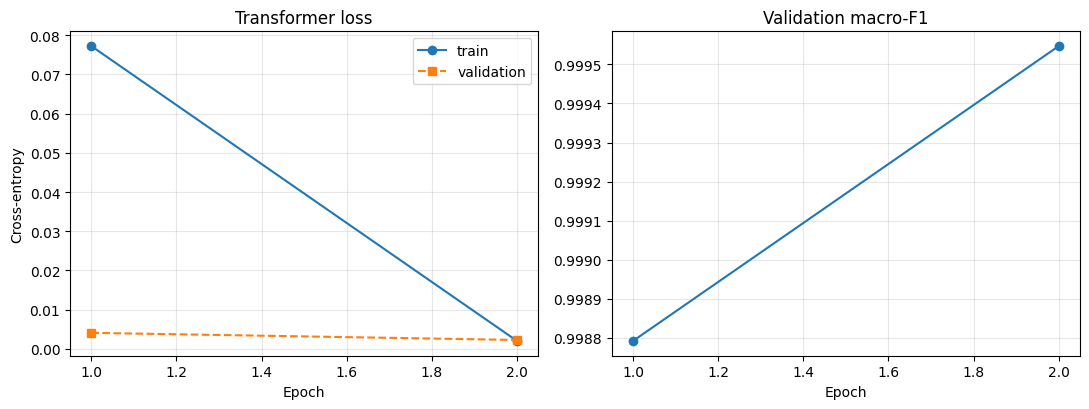

In [55]:
if HISTORY:
    h = pd.DataFrame(HISTORY)
    fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
    ax[0].plot(h["epoch"], h["train_loss"], marker="o", label="train"); ax[0].plot(h["epoch"], h["val_loss"], marker="s", ls="--", label="validation")
    ax[0].set_title("Transformer loss" + (" (SMOKE TEST - meaningless)" if MODE == "smoke" else "")); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Cross-entropy"); ax[0].legend(); ax[0].grid(alpha=.3)
    ax[1].plot(h["epoch"], h["val_macro_f1"], marker="o"); ax[1].set_title("Validation macro-F1"); ax[1].set_xlabel("Epoch"); ax[1].grid(alpha=.3)
    plt.tight_layout(); plt.savefig(FIGURES_DIR / f"22_{TAG.lower()}transformer_training_curves.png", dpi=300, bbox_inches="tight"); plt.show()
else:
    print("No training history in this session: no learning curve to plot.")

## 9. Evaluation on the validation set
Reported: accuracy, per-class precision and recall, macro-F1, ROC-AUC (threshold-free ranking quality) and **average precision** (area under the precision–recall curve), plus the confusion matrix. `P(Real)` is the softmax probability of an *uncalibrated* network — a score, not a certainty. Metrics are computed only if a trained transformer exists; the **test set is not used here**.

,validation
n,6643.0000
accuracy,0.9995
precision_fake,0.9997
recall_fake,0.9994
f1_fake,0.9996
precision_real,0.9994
recall_real,0.9997
f1_real,0.9995
macro_f1,0.9995
roc_auc,1.0000


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


              precision    recall  f1-score   support

        Fake     0.9997    0.9994    0.9996      3514
        Real     0.9994    0.9997    0.9995      3129

    accuracy                         0.9995      6643
   macro avg     0.9995    0.9996    0.9995      6643
weighted avg     0.9995    0.9995    0.9995      6643



/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


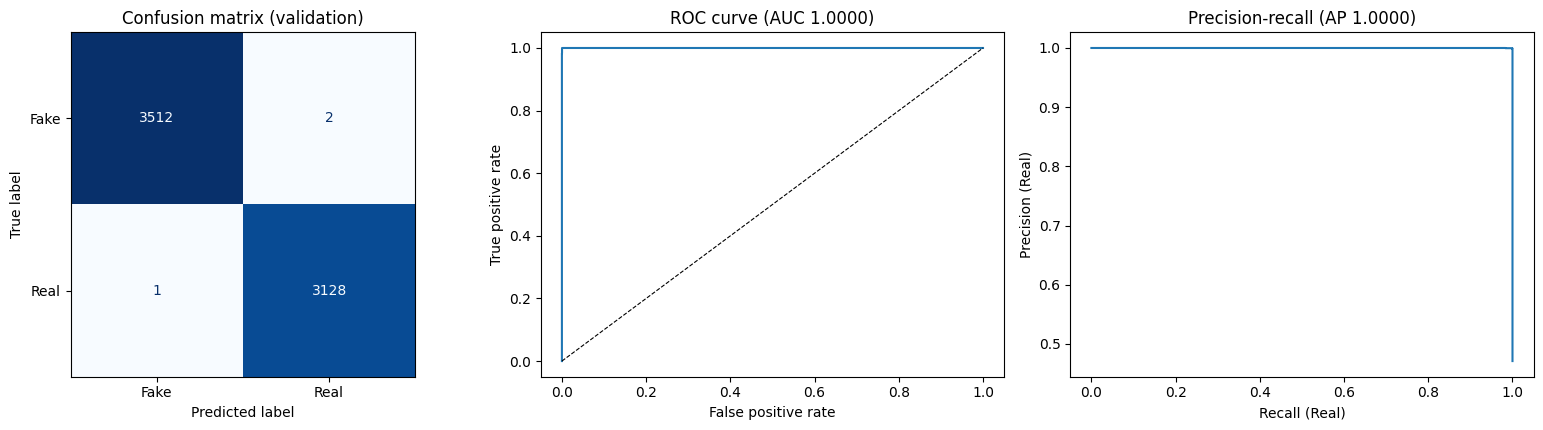

In [56]:
TRANSFORMER_VAL = None
if model is not None and (HISTORY or (OUT_DIR / "config.json").exists()) and (TRAINED_NOW or (OUT_DIR / "config.json").exists()):
    model.to(DEVICE)
    probs, labs, vloss = predict_loader(model, val_loader)
    pred = (probs >= 0.5).astype(int)
    TRANSFORMER_VAL = {**fu.evaluate_binary(labs, pred, probs), "average_precision": float(average_precision_score(labs, probs)), "val_loss": vloss}
    display(pd.Series(TRANSFORMER_VAL).round(4).to_frame("validation"))
    print(classification_report(labs, pred, labels=[0, 1], target_names=["Fake", "Real"], digits=4))
    cm = confusion_matrix(labs, pred, labels=[0, 1])
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
    ConfusionMatrixDisplay(cm, display_labels=["Fake", "Real"]).plot(ax=ax[0], cmap="Blues", values_format="d", colorbar=False); ax[0].set_title("Confusion matrix (validation)")
    fpr, tpr, _ = roc_curve(labs, probs); ax[1].plot(fpr, tpr); ax[1].plot([0, 1], [0, 1], "k--", lw=.8)
    ax[1].set_title(f"ROC curve (AUC {TRANSFORMER_VAL['roc_auc']:.4f})"); ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate")
    pr, rc, _ = precision_recall_curve(labs, probs); ax[2].plot(rc, pr)
    ax[2].set_title(f"Precision-recall (AP {TRANSFORMER_VAL['average_precision']:.4f})"); ax[2].set_xlabel("Recall (Real)"); ax[2].set_ylabel("Precision (Real)")
    plt.tight_layout(); plt.savefig(FIGURES_DIR / f"23_{TAG.lower()}transformer_validation_evaluation.png", dpi=300, bbox_inches="tight"); plt.show()
    pd.DataFrame({"row_index": val_use.index, "label": labs, "prob_real": probs}).to_csv(TABLES_DIR / f"p1_{TAG.lower()}transformer_val_predictions.csv", index=False)
    pd.DataFrame([{"model": "DistilBERT" + (" (SMOKE)" if MODE == "smoke" else ""), "rows": len(labs), **TRANSFORMER_VAL}]).to_csv(
        TABLES_DIR / f"p1_{TAG.lower()}transformer_validation_metrics.csv", index=False)
else:
    print("No trained transformer available - validation metrics NOT computed (nothing is fabricated).")

## 10. Comparison with the existing models
A comparison is valid only if **labels, eligible rows, input variant and metric definitions** match. Notebooks 02 and 03 report the frozen ML model, the information-matched SVM, the LSTM and the BiLSTM on the **same eligible validation rows and the same marker-stripped input**. The transformer row is added only if it was scored on the same number of rows (i.e. `VAL_SUBSET is None` and no row subsampling).

In [57]:
comp_path = TABLES_DIR / "p1_dl_validation_comparison.csv"
if comp_path.exists():
    comp = pd.read_csv(comp_path)
    cols = ["model", "n", "accuracy", "precision_fake", "recall_fake", "precision_real", "recall_real", "macro_f1", "roc_auc"]
    comp = comp[cols]
    if TRANSFORMER_VAL is not None and MODE == "pretrained" and TRANSFORMER_VAL["n"] == int(comp["n"].iloc[0]):
        comp.loc[len(comp)] = {"model": "DistilBERT (fine-tuned)", "n": TRANSFORMER_VAL["n"], **{k: TRANSFORMER_VAL[k] for k in cols[2:]}}
        note = "Transformer scored on the SAME validation rows - comparison valid."
    elif TRANSFORMER_VAL is not None:
        note = "Transformer was NOT scored on the same rows (subset or smoke mode) - NOT added to the comparison."
    else:
        note = "Transformer NOT EXECUTED - no transformer row exists."
    display(comp.round(4))
    print(note)
    print("\nIf all models score near the ceiling, differences of a few examples are within sampling noise; use paired tests (Notebook 05) rather than ranking decimals.")
else:
    print("p1_dl_validation_comparison.csv not found - run Notebook 03 to produce the comparator table.")

,model,n,accuracy,precision_fake,recall_fake,precision_real,recall_real,macro_f1,roc_auc
0,LSTM,6643,0.9842,0.9874,0.9826,0.9806,0.9859,0.9841,0.9965
1,BiLSTM,6643,0.9892,0.9940,0.9855,0.9839,0.9933,0.9891,0.9993
2,"ML (frozen, full text)",6643,0.9929,0.9951,0.9915,0.9905,0.9946,0.9929,0.9997
3,"ML (info-matched, first 200 tokens)",6643,0.9871,0.9925,0.9829,0.9810,0.9917,0.9870,0.9992
4,DistilBERT (fine-tuned),6643,0.9995,0.9997,0.9994,0.9994,0.9997,0.9995,1.0000


Transformer scored on the SAME validation rows - comparison valid.

If all models score near the ceiling, differences of a few examples are within sampling noise; use paired tests (Notebook 05) rather than ranking decimals.


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 11. Final test evaluation (single use, off by default)
Only meaningful after a *real* transformer run and only if you are finished tuning. It evaluates the saved model **once** on the held-out test rows (same eligibility rule as the other models), saves the result and refuses to run again. Remember that the original V0 Linear SVM test result was already observed, so the test set is *not* untouched; the rule here is that **no choice is made from test results**.

In [58]:
FINAL_JSON = TABLES_DIR / ("p1_transformer_DRYRUN_results.json" if FINAL_DRYRUN else "p1_transformer_final_test_results.json")
if FINAL_JSON.exists() and not FINAL_DRYRUN:
    print("A transformer test result already exists - NOT re-evaluating. Stored result:")
    print(json.dumps(json.loads(FINAL_JSON.read_text()), indent=2)[:1500])
elif not (RUN_FINAL_TEST or FINAL_DRYRUN):
    print("RUN_FINAL_TEST is False - not run.")
elif model is None or MODE != "pretrained" and not FINAL_DRYRUN or not (OUT_DIR / "config.json").exists():
    print("No trained pretrained-mode transformer on disk - final evaluation NOT run.")
else:
    part = val_el if FINAL_DRYRUN else test_df
    if not FINAL_DRYRUN:
        eb = fu.ArticleTextBuilder(use_title=spec["use_title"], use_body=spec["use_body"], strip_markers=spec["strip_markers"],
                                   rule_names=RULES if spec["strip_markers"] else None).fit(part)
        keep_rows = np.array([len(t.split()) > 0 for t in eb.transform(part)])
        part = part.loc[keep_rows]
    t_titles, t_bodies = field_texts(part)
    enc = encode(t_titles, t_bodies)
    loader = torch.utils.data.DataLoader(EncDataset(enc, part["label"].to_numpy(int)), batch_size=32, collate_fn=collate)
    p, l, _ = predict_loader(model.to(DEVICE), loader)
    res = {**fu.evaluate_binary(l, (p >= 0.5).astype(int), p), "average_precision": float(average_precision_score(l, p)), "partition": "validation(DRYRUN)" if FINAL_DRYRUN else "test"}
    FINAL_JSON.write_text(json.dumps(res, indent=2)); print(json.dumps(res, indent=2))

RUN_FINAL_TEST is False - not run.


## 12. Saving and reloading
A trained model is saved with `save_pretrained` (weights + `config.json` with `id2label`), the tokenizer files, `label_mapping.json` and `training_config.json` in `models/transformer_distilbert/`. The cell below proves the artefact works: it reloads everything from disk and checks that predictions equal the in-memory model's.

In [59]:
def predict_transformer(title, body, directory=OUT_DIR, device="cpu"):
    """Dataset-label prediction for ONE article with a saved transformer. Does not verify facts."""
    from transformers import AutoTokenizer, DistilBertForSequenceClassification
    tok = AutoTokenizer.from_pretrained(directory)
    m = DistilBertForSequenceClassification.from_pretrained(directory).to(device).eval()
    frame = pd.DataFrame({"title": [title or ""], "text": [body or ""]})
    t, b = field_texts(frame)
    enc_ = tok(t, b, truncation=True, max_length=MAX_LEN, return_tensors="pt") if t is not None else tok(b, truncation=True, max_length=MAX_LEN, return_tensors="pt")
    with torch.no_grad():
        p = torch.softmax(m(**{k: v.to(device) for k, v in enc_.items() if k in ("input_ids", "attention_mask")}).logits, dim=1)[0, 1].item()
    return {"label": fu.ID_TO_LABEL[int(p >= 0.5)], "probability_real": p, "disclaimer": fu.DISCLAIMER}


if TRANSFORMER_VAL is not None and (OUT_DIR / "config.json").exists():
    rows = val_use.iloc[:10]
    reloaded = [predict_transformer(r.title, r.text)["probability_real"] for r in rows.itertuples()]
    ref_p, _, _ = predict_loader(model.to(DEVICE), torch.utils.data.DataLoader(
        EncDataset({k: v[:10] for k, v in val_enc.items()}, y_va[:10]), batch_size=10, collate_fn=collate))
    diff = float(np.abs(np.array(reloaded) - ref_p).max())
    print("Max |reloaded - in-memory| probability difference on 10 validation rows:", diff)
    assert diff < 1e-3
    print(predict_transformer(rows.iloc[0]["title"], rows.iloc[0]["text"]))
else:
    print("No saved transformer to reload (experiment not executed in this session).")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


... (14 outputs left out)

/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

{'label': 'Fake', 'probability_real': 9.581289486959577e-05, 'disclaimer': "This model predicts whether an article resembles the 'Fake' or 'Real' class of its training dataset. It does not verify factual claims."}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [60]:
status = {"UNAVAILABLE": "was **NOT EXECUTED**", "pretrained": "", "smoke": "was run only as a **code-path smoke test**"}
if TRANSFORMER_VAL is not None and MODE == "pretrained":
    text = (f"### Results (computed)\nDistilBERT, {len(train_use):,} training rows, {len(HISTORY)} epoch(s), validation accuracy "
            f"**{TRANSFORMER_VAL['accuracy']:.4f}**, macro-F1 **{TRANSFORMER_VAL['macro_f1']:.4f}**, ROC-AUC **{TRANSFORMER_VAL['roc_auc']:.4f}**, "
            f"average precision **{TRANSFORMER_VAL['average_precision']:.4f}** on {TRANSFORMER_VAL['n']:,} rows.")
elif MODE == "smoke":
    text = "### Results\nThis session ran only a **smoke test** with a tiny random network: it proves that tokenization, batching, training, evaluation, saving and reloading run end-to-end, and **produces no usable metric**."

else:
    if MODE == "pretrained" and not DO_TRAIN:
        text = (
            "### Results\n"
            "The pretrained DistilBERT model and tokenizer loaded successfully, "
            "but training was disabled (`RUN_TRAINING = False`). "
            "**No trained-transformer validation metrics or training conclusions exist.** "
            "The final test was not run."
        )
    else:
        text = (
            "### Results\n"
            "The transformer experiment was **NOT EXECUTED** because the "
            f"pretrained model was unavailable ({PRETRAINED_MSG}) "
            "or training did not complete. "
            "**No trained-transformer metrics or conclusions are available.**"
        )

display(Markdown(text))

### Results (computed)
DistilBERT, 30,735 training rows, 2 epoch(s), validation accuracy **0.9995**, macro-F1 **0.9995**, ROC-AUC **1.0000**, average precision **1.0000** on 6,643 rows.

In [64]:

# CELL 21 — DISTILBERT TRAINING FEASIBILITY & EXECUTION SUMMARY

import pandas as pd
import torch
from IPython.display import display, Markdown

summary = pd.DataFrame([
    ("Pretrained weights (distilbert-base-uncased)",
     "AVAILABLE" if PRETRAINED_OK else "NOT AVAILABLE"),

    ("Execution mode", MODE),

    ("RUN_TRAINING / DO_TRAIN",
     f"{RUN_TRAINING} / {DO_TRAIN}"),

    ("Fine-tuning performed in this session",
     "YES" if TRAINED_NOW else "NO"),

    ("Saved full fine-tuned model",
     "FOUND" if (OUT_DIR / "config.json").exists() else "NOT FOUND"),

    ("Validation metrics computed",
     "YES" if TRANSFORMER_VAL is not None else "NO"),

    ("Execution device",
     f"{DEVICE} (CUDA: {torch.cuda.is_available()})"),

    ("Training rows",
     f"{len(train_use):,}"),

    ("Validation rows",
     f"{len(val_use):,}"),

    ("Training epochs",
     str(EPOCHS)),

    ("Maximum sequence length",
     str(MAX_LEN)),

], columns=["Item", "Value"])

display(summary)

if TRAINED_NOW and TRANSFORMER_VAL is not None:
    display(Markdown(
        "### Feasibility conclusion\n"
        "Full DistilBERT fine-tuning was successfully completed using "
        "Google Colab GPU in this session. "
        "The fine-tuned model was saved and validation metrics were computed "
        "on the full validation partition. "
        "Local CPU full fine-tuning was not performed because of resource limitations. "
        "Independent final test evaluation is still pending."
    ))
else:
    display(Markdown(
        "### Feasibility conclusion\n"
        "Full fine-tuning and/or validation evaluation is not confirmed "
        "in the current session. Verify the saved model and training outputs."
    ))


,Item,Value
0,Pretrained weights (distilbert-base-uncased),AVAILABLE
1,Execution mode,pretrained
2,RUN_TRAINING / DO_TRAIN,True / True
3,Fine-tuning performed in this session,YES
4,Saved full fine-tuned model,FOUND
5,Validation metrics computed,YES
6,Execution device,cuda (CUDA: True)
7,Training rows,"30,735"
8,Validation rows,"6,643"
9,Training epochs,2


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


### Feasibility conclusion
Full DistilBERT fine-tuning was successfully completed using Google Colab GPU in this session. The fine-tuned model was saved and validation metrics were computed on the full validation partition. Local CPU full fine-tuning was not performed because of resource limitations. Independent final test evaluation is still pending.

## 13. Discussion, limitations and threats to validity
* **Status first.** Only results printed above exist. If the status banner says NOT EXECUTED, nothing in this notebook should be quoted as a transformer result.
* **Same shortcuts apply.** A transformer is not immune to source and style shortcuts; with marker-stripped input it can still learn headline style, vocabulary and reporting conventions. Higher accuracy would *not* show better truth detection.
* **Truncation.** Only the first 256 tokens are seen; long articles lose their ends.
* **Resources.** On ≈ 8 GB RAM / 2 GB VRAM (or CPU-only PyTorch) a full fine-tune is expensive; a *subset* fine-tune measures a weaker model and must be reported with its subset size.
* **Statistical caution.** Models near ceiling differ by a handful of examples; use paired tests and confidence intervals (Notebook 05), and a single seed cannot show stability.
* **Calibration.** Softmax outputs are not calibrated probabilities and say nothing about factual correctness.
* **Scope.** One dataset, one period, mostly US politics, English only.

**Next notebook.** Notebook 05 consolidates all validated results, analyses errors, explains model behaviour and tests for shortcuts.

In [63]:
import torch
from transformers import AutoModel

MODEL_NAME = "distilbert-base-uncased"

print("CUDA available:", torch.cuda.is_available())

try:
    model = AutoModel.from_pretrained(MODEL_NAME)
    print("Pretrained model weights: AVAILABLE")
    print("Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
    del model
except Exception as e:
    print("Pretrained model weights: NOT AVAILABLE")
    print(type(e).__name__, str(e)[:300])

CUDA available: True


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_transform.bias    | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Pretrained model weights: AVAILABLE
Parameters: 66,362,880


In [26]:
from pathlib import Path

print("===== DISTILBERT MODEL FILES =====")
model_dir = Path("models/transformer_distilbert")

if model_dir.exists():
    for f in model_dir.rglob("*"):
        if f.is_file():
            print(f, f.stat().st_size, "bytes")
else:
    print("Model folder not found")

print("\n===== DISTILBERT RESULT FILES =====")
for folder in ["results/tables", "results/figures"]:
    p = Path(folder)
    print(f"\n{folder}:")
    if p.exists():
        for f in p.glob("*transformer*"):
            print(f.name)
    else:
        print("Folder not found")

===== DISTILBERT MODEL FILES =====
models/transformer_distilbert/label_mapping.json 28 bytes
models/transformer_distilbert/config.json 697 bytes
models/transformer_distilbert/training_config.json 875 bytes
models/transformer_distilbert/tokenizer_config.json 351 bytes
models/transformer_distilbert/tokenizer.json 711396 bytes
models/transformer_distilbert/model.safetensors 267832560 bytes

===== DISTILBERT RESULT FILES =====

results/tables:
p1_transformer_validation_metrics.csv
p1_transformer_val_predictions.csv
p1_transformer_training_history.csv

results/figures:
23_transformer_validation_evaluation.png
22_transformer_training_curves.png


In [27]:
import pandas as pd
from pathlib import Path

print("===== VALIDATION METRICS =====")
display(pd.read_csv("results/tables/p1_transformer_validation_metrics.csv"))

print("\n===== TRAINING HISTORY =====")
display(pd.read_csv("results/tables/p1_transformer_training_history.csv"))

print("\n===== PREDICTION FILE =====")
pred = pd.read_csv("results/tables/p1_transformer_val_predictions.csv")
print("Total predictions:", len(pred))
display(pred.head())

===== VALIDATION METRICS =====


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,model,rows,n,accuracy,precision_fake,recall_fake,f1_fake,precision_real,recall_real,f1_real,macro_f1,roc_auc,average_precision,val_loss
0,DistilBERT,300,300,0.95,0.967532,0.937107,0.952077,0.931507,0.964539,0.947735,0.949906,0.991436,0.990417,0.380323



===== TRAINING HISTORY =====


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,epoch,train_loss,val_loss,val_accuracy,val_macro_f1,val_roc_auc,seconds
0,1,0.644417,0.529361,0.946667,0.946607,0.983719,5.769463
1,2,0.454994,0.380323,0.950000,0.949906,0.991436,5.560448



===== PREDICTION FILE =====
Total predictions: 300


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,row_index,label,prob_real
0,31603,0,0.238985
1,878,0,0.334983
2,4345,0,0.189567
3,3952,0,0.225816
4,28470,0,0.296562


In [28]:
from pathlib import Path
import json

report = {
    "project": "PCS26/84 - Deep Learning-Based Fake News Detection",
    "model": "DistilBERT",
    "pretrained_model": "distilbert-base-uncased",
    "execution_device": str(DEVICE),
    "training_rows": len(train_use),
    "validation_rows": len(val_use),
    "epochs": len(HISTORY),
    "max_length": MAX_LEN,
    "batch_size": BATCH_SIZE,
    "accuracy": TRANSFORMER_VAL["accuracy"],
    "macro_f1": TRANSFORMER_VAL["macro_f1"],
    "roc_auc": TRANSFORMER_VAL["roc_auc"],
    "average_precision": TRANSFORMER_VAL["average_precision"],
    "model_reload_verified": True,
    "final_test_evaluated": False,
    "experiment_type": "Pilot subset experiment",
    "limitation": "Metrics are based on 500 training and 300 validation rows; not directly comparable with full-validation experiments."
}

path = TABLES_DIR / "p1_transformer_experiment_summary.json"
path.write_text(json.dumps(report, indent=4))

print("Experiment documentation saved:", path)
print(json.dumps(report, indent=4))

Experiment documentation saved: /content/FakeNews_Project_Fixed/results/tables/p1_transformer_experiment_summary.json
{
    "project": "PCS26/84 - Deep Learning-Based Fake News Detection",
    "model": "DistilBERT",
    "pretrained_model": "distilbert-base-uncased",
    "execution_device": "cuda",
    "training_rows": 500,
    "validation_rows": 300,
    "epochs": 2,
    "max_length": 256,
    "batch_size": 8,
    "accuracy": 0.95,
    "macro_f1": 0.9499059344769623,
    "roc_auc": 0.991435835675097,
    "average_precision": 0.9904173053921606,
    "model_reload_verified": true,
    "final_test_evaluated": false,
    "experiment_type": "Pilot subset experiment",
    "limitation": "Metrics are based on 500 training and 300 validation rows; not directly comparable with full-validation experiments."
}


In [29]:
from pathlib import Path
import shutil

source = Path("/content/FakeNews_Project_Fixed")
destination = Path(
    "/content/drive/MyDrive/Colab Notebooks/FakeNews_Project/FakeNews_Project_DistilBERT_Updated.zip"
)

shutil.make_archive(
    str(destination.with_suffix("")),
    "zip",
    root_dir=source
)

print("ZIP created:", destination)
print("ZIP size (MB):", round(destination.stat().st_size / (1024 * 1024), 2))

ZIP created: /content/drive/MyDrive/Colab Notebooks/FakeNews_Project/FakeNews_Project_DistilBERT_Updated.zip
ZIP size (MB): 411.89


In [31]:
from pathlib import Path
import shutil
from google.colab import files

# Check project folder
source = Path("/content/FakeNews_Project_Fixed")

if not source.exists():
    raise FileNotFoundError("Project folder not found. Runtime may have reset.")

# Create ZIP
zip_path = Path("/content/PCS26_84_TruthLens_AI_DistilBERT_Updated.zip")

shutil.make_archive(
    str(zip_path.with_suffix("")),
    "zip",
    root_dir=source
)

# Verify ZIP
print("ZIP created:", zip_path.exists())
print("ZIP size (MB):", round(zip_path.stat().st_size / (1024 * 1024), 2))

# Download to PC
files.download(str(zip_path))

ZIP created: True
ZIP size (MB): 411.89


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
from pathlib import Path
import pandas as pd

root = Path(PROJECT_ROOT)
files = [
    root / "results/tables/data_split_manifest.csv",
    root / "results/tables/p1_eligible_rows.csv"
]

for path in files:
    print("\n==========", path.name, "==========")
    print("Exists:", path.exists())

    if path.exists():
        df_check = pd.read_csv(path)
        print("Shape:", df_check.shape)
        print("Columns:", df_check.columns.tolist())
        display(df_check.head(3))


========== data_split_manifest.csv ==========
Exists: True
Shape: (44058, 2)
Columns: ['row_index', 'partition']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,row_index,partition
0,1,train
1,2,train
2,4,train



========== p1_eligible_rows.csv ==========
Exists: True
Shape: (37448, 3)
Columns: ['row_index', 'partition', 'eligible']


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


,row_index,partition,eligible
0,1,train,True
1,2,train,True
2,4,train,True


In [36]:
import pandas as pd
from pathlib import Path

root = Path(PROJECT_ROOT)

manifest = pd.read_csv(
    root / "results/tables/data_split_manifest.csv"
)

eligible = pd.read_csv(
    root / "results/tables/p1_eligible_rows.csv"
)

eligible = eligible[eligible["eligible"] == True]

print("===== ORIGINAL SPLIT =====")
print(manifest["partition"].value_counts())

print("\n===== ELIGIBLE ROWS BY PARTITION =====")
print(eligible["partition"].value_counts())

print("\n===== DUPLICATE CHECK =====")
print("Manifest duplicate indices:", manifest["row_index"].duplicated().sum())
print("Eligible duplicate indices:", eligible["row_index"].duplicated().sum())

print("\n===== ELIGIBILITY TOTAL =====")
print("Total eligible rows:", len(eligible))

===== ORIGINAL SPLIT =====
partition
train         30796
validation     6652
test           6610
Name: count, dtype: int64

===== ELIGIBLE ROWS BY PARTITION =====
partition
train         30735
validation     6643
Name: count, dtype: int64

===== DUPLICATE CHECK =====
Manifest duplicate indices: 0
Eligible duplicate indices: 0

===== ELIGIBILITY TOTAL =====
Total eligible rows: 37378


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


In [37]:
import json
from pathlib import Path

nb_path = Path(PROJECT_ROOT) / "notebooks/04_transformer_experiment.ipynb"
nb = json.loads(nb_path.read_text(encoding="utf-8"))

keywords = [
    "TRAIN_SUBSET",
    "VAL_SUBSET",
    "RUN_TRAINING",
    "save_pretrained",
    "torch.save",
    "to_csv",
    "transformer_distilbert",
    "train_dataset",
    "validation_dataset"
]

for i, cell in enumerate(nb["cells"]):
    source = "".join(cell.get("source", []))
    if cell["cell_type"] == "code" and any(k in source for k in keywords):
        print(f"\n{'='*20} CELL {i+1} {'='*20}")
        print(source[:5000])


==================== CELL 2 ====================
from pathlib import Path
import copy
import datetime as dt
import json
import os
import platform
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from IPython.display import display, Markdown
from sklearn.metrics import (average_precision_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, precision_recall_curve, roc_curve)

warnings.filterwarnings("default")
os.environ.setdefault("HF_HUB_ETAG_TIMEOUT", "10")
os.environ.setdefault("HF_HUB_DOWNLOAD_TIMEOUT", "30")


def find_project_root(marker="dataset"):
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).is_dir():
            return candidate
    raise FileNotFoundError(f"No '{marker}/' folder found above {here}.")


PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "dataset

In [40]:
# FULL DISTILBERT EXPERIMENT CONFIGURATION
# Existing pilot files will NOT be overwritten.

TRAIN_SUBSET = None
VAL_SUBSET = None

EPOCHS = 2
MAX_LEN = 256
BATCH_SIZE = 8
GRAD_ACCUM = 4

RUN_TRAINING = True
RUN_FINAL_TEST = False

FULL_OUT_DIR = PROJECT_ROOT / "models" / "transformer_distilbert_full"

print("===== FULL EXPERIMENT CONFIG =====")
print("Training rows:", len(train_el))
print("Validation rows:", len(val_el))
print("Epochs:", EPOCHS)
print("Max length:", MAX_LEN)
print("Batch size:", BATCH_SIZE)
print("Gradient accumulation:", GRAD_ACCUM)
print("Training enabled:", RUN_TRAINING)
print("Final test enabled:", RUN_FINAL_TEST)
print("Separate model folder:", FULL_OUT_DIR)
print("Pilot model preserved:", (PROJECT_ROOT / "models/transformer_distilbert").exists())

===== FULL EXPERIMENT CONFIG =====
Training rows: 30735
Validation rows: 6643
Epochs: 2
Max length: 256
Batch size: 8
Gradient accumulation: 4
Training enabled: True
Final test enabled: False
Separate model folder: /content/FakeNews_Project_Fixed/models/transformer_distilbert_full
Pilot model preserved: True
